# TimesFM 2.5 (200M): Zero-Shot Forecasting on ETTh1

**Paper**: *A decoder-only foundation model for time-series forecasting*, Das, Kong, Sen & Zhou (Google Research), **ICML 2024**. [arXiv:2310.10688](https://arxiv.org/abs/2310.10688)

**Official code**: [google-research/timesfm](https://github.com/google-research/timesfm) · **Checkpoint**: [`google/timesfm-2.5-200m-pytorch`](https://huggingface.co/google/timesfm-2.5-200m-pytorch) · **Package**: `timesfm==3.0.2` (PyPI)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/timesfm25_zero_shot.ipynb)

This is the **zero-shot** counterpart of [`finetune_timesfm.ipynb`](https://github.com/manmeet3591/time_series/blob/main/finetune_timesfm.ipynb), which LoRA-fine-tunes the same model with HF `transformers`. Here no weight is updated: we load the pretrained checkpoint and forecast ETTh1 directly.

**Key ideas**:
- **Decoder-only, patched transformer**: the series is cut into input patches of 32 points. Each patch becomes one token, and causal self-attention predicts the next **output patch of 128 points**. Longer horizons are decoded autoregressively.
- **Pretrained on ~100B real and synthetic time points** (Google Trends, Wikipedia page views, M4, electricity, traffic, weather, synthetic ARMA/seasonal series). The paper holds the ETT datasets out of pretraining and uses them as zero-shot benchmarks, which is how we use them here.
- **TimesFM 2.5 vs. the paper's 1.0**: 200M params (down from 500M in 2.0), context up to **16k** (up from 512/2048), an optional **continuous quantile head** (10%–90%) and flip-invariance. The core recipe from the paper is unchanged.
- **Covariates (XReg)**: `forecast_with_covariates` fits an in-context ridge regression on exogenous variables and combines it with TimesFM.

**Protocol**: we use the shared benchmark setup of this repo (ETTh1, standard 12/4/4-month splits, StandardScaler fitted on train, H = 96, stride-1 test windows, MSE/MAE on scaled data). TimesFM is univariate, so **each of the 7 channels is forecast independently** (channel-independent), and all `windows × channels` series are batched on the GPU. Foundation models use lookback **L = 512**, and we also report **L = 96** to match the supervised baselines.

In [1]:
%pip install -q "timesfm[torch,xreg]==3.0.2"

Note: you may need to restart the kernel to use updated packages.


## Setup

XReg uses JAX for its ridge solver. We pin JAX to the CPU **before** importing it. Otherwise JAX would grab ~75% of GPU memory alongside PyTorch, and the regression is tiny anyway.

In [2]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # XReg's ridge solve runs on CPU; keeps the GPU for TimesFM

import time, json, random, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import timesfm
warnings.filterwarnings("ignore")

SEED = 2024
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"   # timesfm picks cuda:0 automatically if available
print(f"Using device: {device}", f"({torch.cuda.get_device_name(0)})" if device == "cuda" else "")
print("timesfm", getattr(timesfm, "__version__", "3.0.2"), "| torch", torch.__version__)

Using device: cuda (NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition)
timesfm 3.0.2 | torch 2.12.1+cu130


## Data: ETTh1 (shared benchmark split)

7 hourly channels (HUFL, HULL, MUFL, MULL, LUFL, LULL, OT). Standard borders are 12 months train, 4 val and 4 test. The scaler is fitted on train rows only. TimesFM needs no training, so only the **test** split is used. The val/train splits are kept for an identical setup.

In [3]:
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])

H = 96
_, _, test512, cols = load_etth1(512)
_, _, test96, _ = load_etth1(96)
print("channels:", cols)
print("test (L=512):", test512.shape, "->", len(WindowDataset(test512, 512, H)), "windows")
print("test (L=96): ", test96.shape, "->", len(WindowDataset(test96, 96, H)), "windows")

channels: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
test (L=512): (3392, 7) -> 2785 windows
test (L=96):  (2976, 7) -> 2785 windows


## Model: loading the pretrained TimesFM 2.5 checkpoint

A context $x_{1:L}$ is split into patches $\tilde{x}_j = x_{32(j-1)+1 : 32j}$. Each patch, together with its padding mask, is embedded by a residual MLP:
$$t_j = \text{ResBlock}([\tilde{x}_j \odot (1-\tilde{m}_j);\ \tilde{m}_j]),$$
then passed through 20 causal transformer layers (d = 1280, 16 heads, RoPE, QK-norm). The output token $o_j$ is mapped to the **next 128 points**, $\hat{x}_{32j+1:32j+128} = \text{ResBlock}(o_j)$, plus a quantile head. Each patch is reversibly normalised (RevIN-style) with the series' **causal running mean/std** up to that patch, and outputs are de-normalised with the same statistics.

`from_pretrained` downloads `model.safetensors` (~0.9 GB) from the HF Hub. We disable `torch.compile`: the decode loop has graph breaks, so compiling adds start-up time with no measurable speed-up.

In [4]:
t0 = time.time()
model = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch", torch_compile=False)
n_params = sum(p.numel() for p in model.model.parameters())
print(f"Loaded in {time.time()-t0:.1f}s | parameters: {n_params/1e6:.1f}M | device: {model.model.device}")

Loaded in 1.4s | parameters: 231.3M | device: cuda:0


## Forecast configuration

`compile()` sets the decoding options. It is a Python closure, not `torch.compile`, so it is cheap and can be called again whenever the options change:

| flag | meaning |
|---|---|
| `max_context` | context is left-padded/truncated to this length (rounded up to a multiple of 32) |
| `max_horizon` | decoded horizon, rounded up to a multiple of 128. H = 96 fits in **one** output patch, so there is no autoregressive roll-out |
| `normalize_inputs` | extra per-series z-normalisation before the model |
| `use_continuous_quantile_head` | use the dedicated quantile head, which avoids quantile collapse (valid for horizons ≤ 1024) |
| `force_flip_invariance` | average $f(x)$ and $-f(-x)$ so that $f(ax+b)=af(x)+b$ also holds for $a<0$. This costs 2× compute |
| `infer_is_positive` | clip forecasts at 0 if the context is non-negative. **Turned off**: our data are z-scored, so the sign carries no meaning |
| `fix_quantile_crossing` | enforce monotone quantiles |

`forecast()` returns `point` of shape `(N, H)` and `quantiles` of shape `(N, H, 10)`. Index 0 of the quantiles is the mean and indices 1–9 are the 10%…90% quantiles. The **point forecast is the median** (index 5).

In [5]:
BATCH = 512   # series per forward pass; ~4 GB at L=512 with flip-invariance. Lower it on small GPUs.

def make_config(L, return_backcast=False):
    return timesfm.ForecastConfig(
        max_context=L, max_horizon=128,
        normalize_inputs=True,
        use_continuous_quantile_head=True,
        force_flip_invariance=True,
        infer_is_positive=False,
        fix_quantile_crossing=True,
        return_backcast=return_backcast,
        per_core_batch_size=BATCH,
    )

def evaluate_zero_shot(test, L, H=96, stride=1):
    # Channel-independent zero-shot evaluation over all stride-1 test windows.
    ds = WindowDataset(test, L, H, stride)
    X = np.stack([test[i:i+L] for i in ds.idx])                 # (W, L, C)
    Y = np.stack([test[i+L:i+L+H] for i in ds.idx])             # (W, H, C)
    W, _, C = X.shape
    inputs = list(X.transpose(0, 2, 1).reshape(W * C, L))       # one univariate series per (window, channel)
    model.compile(make_config(L))
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    point, quant = model.forecast(horizon=H, inputs=inputs)
    if device == "cuda": torch.cuda.synchronize()
    secs = time.time() - t0
    P = point.reshape(W, C, H).transpose(0, 2, 1)               # (W, H, C)
    Q = quant.reshape(W, C, H, 10).transpose(0, 2, 1, 3)        # (W, H, C, 10)
    return dict(X=X, Y=Y, P=P, Q=Q, secs=secs, n_series=W * C, idx=ds.idx,
                mse=float(((P - Y) ** 2).mean()), mae=float(np.abs(P - Y).mean()))

## Zero-shot evaluation: L = 512 (foundation-model setting)

2785 windows × 7 channels = **19,495 univariate series**, each forecast 96 steps ahead in one batched pass.

In [6]:
res512 = evaluate_zero_shot(test512, L=512)
print(f"L=512 | {res512['n_series']} series in {res512['secs']:.1f}s | MSE {res512['mse']:.4f} | MAE {res512['mae']:.4f}")

L=512 | 19495 series in 30.8s | MSE 0.3844 | MAE 0.3821


## Zero-shot evaluation: L = 96 (same lookback as the supervised baselines)

In [7]:
res96 = evaluate_zero_shot(test96, L=96)
print(f"L=96  | {res96['n_series']} series in {res96['secs']:.1f}s | MSE {res96['mse']:.4f} | MAE {res96['mae']:.4f}")

L=96  | 19495 series in 10.8s | MSE 0.4289 | MAE 0.4024


### Per-channel breakdown and probabilistic calibration

TimesFM also produces quantiles. We check the empirical coverage of the 10–90% band (ideal 80%) and the mean **quantile (pinball) loss**:
$$\rho_\tau(y,\hat q_\tau) = \max\big(\tau (y-\hat q_\tau),\ (\tau-1)(y-\hat q_\tau)\big),\quad \tau\in\{0.1,\dots,0.9\}.$$

In [8]:
taus = np.arange(1, 10) / 10
def prob_metrics(r):
    Y, Q = r["Y"], r["Q"][..., 1:]                               # (W,H,C,9)
    cover = float(((Y >= Q[..., 0]) & (Y <= Q[..., -1])).mean())
    d = Y[..., None] - Q
    pinball = float(np.maximum(taus * d, (taus - 1) * d).mean())
    return cover, pinball

rows = []
for name, r in [("L=512", res512), ("L=96", res96)]:
    for c, ch in enumerate(cols):
        rows.append(dict(setting=name, channel=ch,
                         MSE=((r["P"][..., c] - r["Y"][..., c]) ** 2).mean(),
                         MAE=np.abs(r["P"][..., c] - r["Y"][..., c]).mean()))
per_ch = pd.DataFrame(rows).pivot(index="channel", columns="setting", values=["MSE", "MAE"]).loc[cols]
print(per_ch.round(4).to_string())
for name, r in [("L=512", res512), ("L=96", res96)]:
    cov, pb = prob_metrics(r)
    r["cov80"], r["pinball"] = cov, pb
    print(f"{name}: 10-90% band coverage = {cov:.3f} (ideal 0.80) | mean pinball loss = {pb:.4f}")

            MSE             MAE        
setting   L=512    L=96   L=512    L=96
channel                                
HUFL     0.8068  0.9136  0.5696  0.5899
HULL     0.2036  0.2205  0.3343  0.3519
MUFL     0.8390  0.9215  0.5614  0.5703
MULL     0.1620  0.1805  0.2884  0.3094
LUFL     0.5048  0.5662  0.4812  0.5235
LULL     0.1237  0.1393  0.2702  0.2859
OT       0.0506  0.0606  0.1698  0.1861
L=512: 10-90% band coverage = 0.769 (ideal 0.80) | mean pinball loss = 0.1513


L=96: 10-90% band coverage = 0.774 (ideal 0.80) | mean pinball loss = 0.1615


## Forecast plot with quantile bands (OT channel)

Input history, ground truth, the median forecast and the 10–90% / 20–80% bands. One test window is shown for each lookback, and both panels forecast the same target period.

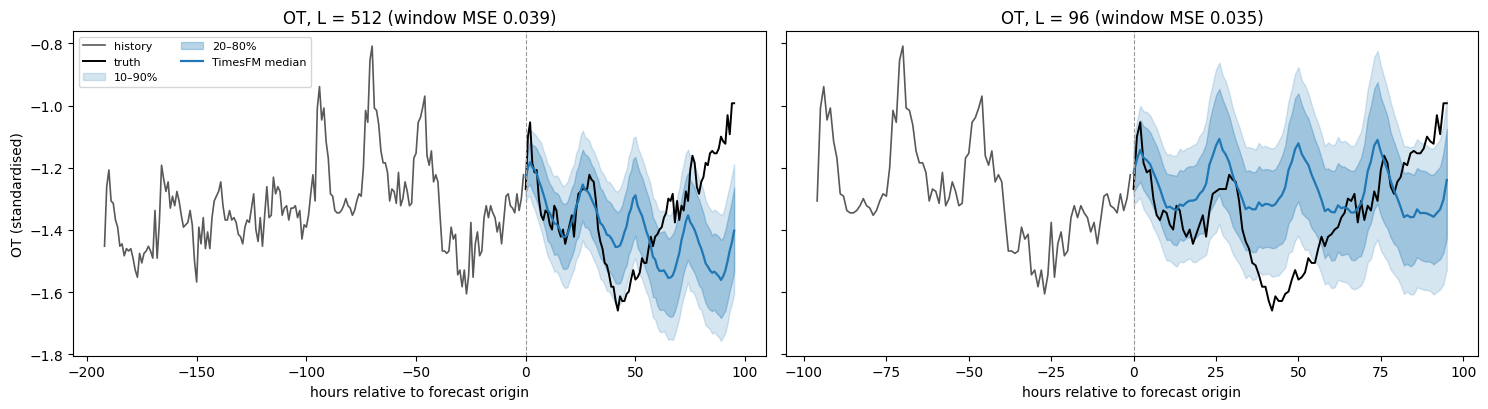

In [9]:
ot = cols.index("OT")
k = 1500                                   # window index (same target period for both lookbacks)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, (name, r, L) in zip(axes, [("L = 512", res512, 512), ("L = 96", res96, 96)]):
    hist = r["X"][k, :, ot]; y = r["Y"][k, :, ot]; p = r["P"][k, :, ot]; q = r["Q"][k, :, ot]
    show = min(L, 192)
    th = np.arange(-show, 0); tf = np.arange(0, H)
    ax.plot(th, hist[-show:], color="0.35", lw=1.2, label="history")
    ax.plot(tf, y, color="black", lw=1.4, label="truth")
    ax.fill_between(tf, q[:, 1], q[:, 9], color="C0", alpha=0.18, label="10–90%")
    ax.fill_between(tf, q[:, 2], q[:, 8], color="C0", alpha=0.30, label="20–80%")
    ax.plot(tf, p, color="C0", lw=1.6, label="TimesFM median")
    ax.axvline(0, color="0.6", ls="--", lw=0.8)
    mse_k = ((p - y) ** 2).mean()
    ax.set_title(f"OT, {name} (window MSE {mse_k:.3f})"); ax.set_xlabel("hours relative to forecast origin")
axes[0].set_ylabel("OT (standardised)"); axes[0].legend(loc="upper left", fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

## Covariates with XReg (OT as target)

TimesFM 2.5 supports exogenous covariates through `forecast_with_covariates`. For every series it fits an **in-context linear (ridge) model** on the covariates over the context window, then combines it with TimesFM in one of two modes:

- `"xreg + timesfm"`: fit $y \approx X\beta$ on the context, then let TimesFM forecast the residual $y - X\beta$. Final forecast: $X_{\text{future}}\beta + \text{TimesFM}(y - X\beta)$.
- `"timesfm + xreg"`: run TimesFM first, then fit the ridge model on TimesFM's in-sample (backcast) residuals.

Dynamic covariates must cover **context + horizon**: their future values must be known. This needs `return_backcast=True` in the config, so we re-`compile`. We evaluate on OT only, with every 24th test window (117 windows, L = 512), using two covariate sets:

1. **Calendar** (hour-of-day, day-of-week, categorical): known in advance, so this is a legitimate real-world setup.
2. **Oracle loads** (the 6 other ETTh1 channels, numerical): their future values would *not* be known in practice. This gives an **upper bound** on how much covariates can help, not a fair benchmark.

In [10]:
L_x, stride_x = 512, 24
dates = pd.to_datetime(pd.read_csv(URL)["date"])
n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
tdates = dates[n_tr + n_va - L_x: n_tr + n_va + n_te].reset_index(drop=True)
idx_x = np.arange(0, len(test512) - L_x - H + 1, stride_x)

ctx_ot = [test512[i:i+L_x, ot].astype(np.float64) for i in idx_x]
Y_ot = np.stack([test512[i+L_x:i+L_x+H, ot] for i in idx_x])

model.compile(make_config(L_x))
p_plain, _ = model.forecast(horizon=H, inputs=list(ctx_ot))

model.compile(make_config(L_x, return_backcast=True))       # XReg needs the in-sample backcast
covsets = {
    "calendar": dict(dynamic_categorical_covariates={
        "hour": [tdates.dt.hour.values[i:i+L_x+H].tolist() for i in idx_x],
        "dow":  [tdates.dt.dayofweek.values[i:i+L_x+H].tolist() for i in idx_x]}),
    "oracle loads": dict(dynamic_numerical_covariates={
        ch: [test512[i:i+L_x+H, j].tolist() for i in idx_x] for j, ch in enumerate(cols) if ch != "OT"}),
}
xrows = [dict(covariates="none (TimesFM only)", mode="-", MSE=((p_plain - Y_ot) ** 2).mean(), MAE=np.abs(p_plain - Y_ot).mean())]
xreg_preds = {}
for cname, kw in covsets.items():
    for mode in ["xreg + timesfm", "timesfm + xreg"]:
        pt, qt = model.forecast_with_covariates(inputs=list(ctx_ot), xreg_mode=mode, ridge=1.0, force_on_cpu=True, **kw)
        pt = np.stack(pt); xreg_preds[(cname, mode)] = pt
        xrows.append(dict(covariates=cname, mode=mode, MSE=((pt - Y_ot) ** 2).mean(), MAE=np.abs(pt - Y_ot).mean()))
xreg_df = pd.DataFrame(xrows)
print(f"OT only, L={L_x}, {len(idx_x)} windows (stride {stride_x})")
print(xreg_df.round(4).to_string(index=False))

OT only, L=512, 117 windows (stride 24)
         covariates           mode    MSE    MAE
none (TimesFM only)              - 0.0496 0.1675
           calendar xreg + timesfm 0.0576 0.1815
           calendar timesfm + xreg 0.0524 0.1740
       oracle loads xreg + timesfm 0.0480 0.1655
       oracle loads timesfm + xreg 0.0523 0.1737


On ETTh1-OT, calendar covariates do **not** help. TimesFM already captures the daily cycle from 512 hours of context, and the in-context regression mainly adds variance. Even oracle future loads give only a small gain. XReg pays off most when covariates carry information the target history lacks, such as promotions, holidays or weather forecasts.

## Results

In [11]:
ref = pd.DataFrame([
    ["TimesFM 2.5 zero-shot (this notebook), L=512", res512["mse"], res512["mae"]],
    ["TimesFM 2.5 zero-shot (this notebook), L=96",  res96["mse"],  res96["mae"]],
    ["TimesFM 1.0 zero-shot (paper Tab. 5, L=512, last test window only)", np.nan, 0.45],
    ["DLinear (supervised, L=96, TSLib)",      0.386, 0.400],
    ["PatchTST (supervised, L=96, TSLib)",     0.414, 0.419],
    ["iTransformer (supervised, L=96, TSLib)", 0.386, 0.405],
    ["TimesNet (supervised, L=96, TSLib)",     0.384, 0.402],
], columns=["model", "MSE", "MAE"])
print("ETTh1, H=96, all 7 channels, scaled data, stride-1 test windows")
print(ref.round(3).to_string(index=False))
print(f"\nInference time: L=512 {res512['secs']:.1f}s, L=96 {res96['secs']:.1f}s ({device}); params {n_params/1e6:.1f}M")
print("Note: the paper reports MAE only, on the LAST test window, for TimesFM 1.0 (200M, ICML 2024). Not directly comparable to a full rolling evaluation.")

results = {
    "model": "TimesFM 2.5 (200M, google/timesfm-2.5-200m-pytorch)",
    "paper": "A decoder-only foundation model for time-series forecasting (Das et al.), arXiv 2310.10688",
    "venue": "ICML 2024",
    "type": "zero-shot foundation",
    "lookback": 512, "horizon": H,
    "mse": res512["mse"], "mae": res512["mae"],
    "paper_mse": None, "paper_mae": 0.45,
    "params": int(n_params),
    "train_or_infer_seconds": round(res512["secs"], 2),
    "mse_L96": res96["mse"], "mae_L96": res96["mae"], "infer_seconds_L96": round(res96["secs"], 2),
    "coverage_10_90_L512": res512["cov80"], "pinball_L512": res512["pinball"],
    "xreg_OT_L512_stride24": xreg_df.round(5).to_dict(orient="records"),
    "notes": ("timesfm==3.0.2; channel-independent univariate forecasting; stride-1 test windows (2785 x 7 series); "
              "point = median; normalize_inputs, continuous quantile head, flip invariance, infer_is_positive=False. "
              "paper_mae is TimesFM 1.0 zero-shot ETTh1 H=96 MAE from arXiv 2310.10688 Table 5 (last test window only, L=512); "
              "the paper reports no MSE."),
}
try:
    with open(f"results_{'timesfm25_zero_shot'}.json", "w") as f:
        json.dump(results, f, indent=2, default=float)
    print("\nwrote results_timesfm25_zero_shot.json")
except Exception as e:
    print("could not write results JSON:", e)

ETTh1, H=96, all 7 channels, scaled data, stride-1 test windows
                                                             model   MSE   MAE
                      TimesFM 2.5 zero-shot (this notebook), L=512 0.384 0.382
                       TimesFM 2.5 zero-shot (this notebook), L=96 0.429 0.402
TimesFM 1.0 zero-shot (paper Tab. 5, L=512, last test window only)   NaN 0.450
                                 DLinear (supervised, L=96, TSLib) 0.386 0.400
                                PatchTST (supervised, L=96, TSLib) 0.414 0.419
                            iTransformer (supervised, L=96, TSLib) 0.386 0.405
                                TimesNet (supervised, L=96, TSLib) 0.384 0.402

Inference time: L=512 30.8s, L=96 10.8s (cuda); params 231.3M
Note: the paper reports MAE only, on the LAST test window, for TimesFM 1.0 (200M, ICML 2024). Not directly comparable to a full rolling evaluation.

wrote results_timesfm25_zero_shot.json


## Using your own data

```python
model = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch", torch_compile=False)
model.compile(timesfm.ForecastConfig(max_context=1024, max_horizon=256, normalize_inputs=True,
                                     use_continuous_quantile_head=True, force_flip_invariance=True,
                                     infer_is_positive=True,          # keep True for raw, non-negative data (sales, counts)
                                     fix_quantile_crossing=True, per_core_batch_size=256))
series = [df["y"].values for _, df in my_df.groupby("id")]  # list of 1-D arrays, lengths may differ
point, quantiles = model.forecast(horizon=168, inputs=series)  # (N, 168), (N, 168, 10): mean, q10..q90
```

- **No scaling needed**: TimesFM normalises each series internally. Raw units are fine. Leading NaNs are stripped and inner NaNs are linearly interpolated.
- **Context**: up to 16k points. Longer contexts generally help (compare L = 512 with L = 96 above), at a linear cost.
- **Multivariate data**: pass every channel as its own series (as done here), or use `forecast_with_covariates` when exogenous drivers with **known future values** exist.
- **Gotcha**: `forecast()` appends padding to the `inputs` list you pass in. Pass a copy (`list(...)`) if you reuse the list.
- **Adapting to your domain**: if zero-shot accuracy is not enough, see [`finetune_timesfm.ipynb`](https://github.com/manmeet3591/time_series/blob/main/finetune_timesfm.ipynb) (LoRA fine-tuning of the same checkpoint).